# Dataset preparation

探索广告投放是否有效增加了利润

SKU (Stock Keeping Unit)
QTY (Quantity)
Sq_Ft (Square Feet)

In [ ]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

main_file_path = '/content/drive/MyDrive/Colab Notebooks/RoundRoastersTransactions.csv'
main_df = pd.read_csv(main_file_path)
print(main_df.info())
print(main_df['StoreID'].nunique())

Mounted at /content/drive
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4332333 entries, 0 to 4332332
Data columns (total 10 columns):
 #   Column          Dtype  
---  ------          -----  
 0   StoreID         int64  
 1   Invoice Number  int64  
 2   Invoice Date    object 
 3   SKU             int64  
 4   Category        object 
 5   Product         object 
 6   QTY             int64  
 7   Size            object 
 8   Gross Margin    float64
 9   Sales           float64
dtypes: float64(2), int64(4), object(4)
memory usage: 330.5+ MB
None
133


In [ ]:
treat_file_path = '/content/drive/MyDrive/Colab Notebooks/treatment-stores (1).csv'
treatstores_df = pd.read_csv(treat_file_path)
print(treatstores_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   StoreID                  10 non-null     int64  
 1   Sq_Ft                    10 non-null     int64  
 2   AvgMonthSales            10 non-null     int64  
 3   Phone Number             9 non-null      object 
 4   Street Combined          10 non-null     object 
 5   Street 1                 10 non-null     object 
 6   Street 2                 1 non-null      float64
 7   Street 3                 1 non-null      object 
 8   City                     10 non-null     object 
 9   Postal Code              10 non-null     int64  
 10  Region                   10 non-null     object 
 11  Country                  10 non-null     object 
 12  Coordinates              10 non-null     object 
 13  Latitude                 10 non-null     float64
 14  Longitude                10 n

In [ ]:
merged_df = pd.merge(main_df, treatstores_df, on='StoreID', how='left')
print(merged_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4332333 entries, 0 to 4332332
Data columns (total 29 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   StoreID                  int64  
 1   Invoice Number           int64  
 2   Invoice Date             object 
 3   SKU                      int64  
 4   Category                 object 
 5   Product                  object 
 6   QTY                      int64  
 7   Size                     object 
 8   Gross Margin             float64
 9   Sales                    float64
 10  Sq_Ft                    float64
 11  AvgMonthSales            float64
 12  Phone Number             object 
 13  Street Combined          object 
 14  Street 1                 object 
 15  Street 2                 float64
 16  Street 3                 object 
 17  City                     object 
 18  Postal Code              float64
 19  Region                   object 
 20  Country                  object 
 21  Coordina

In [ ]:
treat_data = merged_df[merged_df['Sq_Ft'].notna()]
treat_data.to_csv('/content/drive/MyDrive/Colab Notebooks/treat_data.csv', index=False)

print(treat_data.info())

<class 'pandas.core.frame.DataFrame'>
Index: 322900 entries, 1619567 to 2276495
Data columns (total 29 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   StoreID                  322900 non-null  int64  
 1   Invoice Number           322900 non-null  int64  
 2   Invoice Date             322900 non-null  object 
 3   SKU                      322900 non-null  int64  
 4   Category                 322900 non-null  object 
 5   Product                  322900 non-null  object 
 6   QTY                      322900 non-null  int64  
 7   Size                     230242 non-null  object 
 8   Gross Margin             322900 non-null  float64
 9   Sales                    322900 non-null  float64
 10  Sq_Ft                    322900 non-null  float64
 11  AvgMonthSales            322900 non-null  float64
 12  Phone Number             288710 non-null  object 
 13  Street Combined          322900 non-null  object 
 14  St

In [ ]:
allstores_file_path = '/content/drive/MyDrive/Colab Notebooks/round-roaster-stores (1).csv'

allstores_df = pd.read_csv(allstores_file_path)
print(allstores_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 133 entries, 0 to 132
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   StoreID                  133 non-null    int64  
 1   Sq_Ft                    133 non-null    int64  
 2   AvgMonthSales            133 non-null    int64  
 3   Right_Name               133 non-null    object 
 4   Phone Number             130 non-null    object 
 5   Street Combined          133 non-null    object 
 6   Street 1                 133 non-null    object 
 7   Street 2                 37 non-null     object 
 8   Street 3                 25 non-null     object 
 9   City                     133 non-null    object 
 10  State                    133 non-null    object 
 11  Postal Code              133 non-null    int64  
 12  Region                   133 non-null    object 
 13  Country                  133 non-null    object 
 14  Coordinates              1

In [ ]:
unmatched_data = merged_df[merged_df['Sq_Ft'].isna()][['StoreID', 'Invoice Number', 'Invoice Date', 'SKU', 'Category', 'Product', 'QTY', 'Size', 'Gross Margin', 'Sales']]
# print(unmatched_data.info())

merged_df_1 = pd.merge(unmatched_data, allstores_df, on='StoreID', how='left')
print(merged_df_1.info())

control_data = merged_df_1[merged_df_1['Sq_Ft'].notna()]
control_data.to_csv('/content/drive/MyDrive/Colab Notebooks/control_data.csv', index=False)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009433 entries, 0 to 4009432
Data columns (total 29 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   StoreID                  int64  
 1   Invoice Number           int64  
 2   Invoice Date             object 
 3   SKU                      int64  
 4   Category                 object 
 5   Product                  object 
 6   QTY                      int64  
 7   Size                     object 
 8   Gross Margin             float64
 9   Sales                    float64
 10  Sq_Ft                    int64  
 11  AvgMonthSales            int64  
 12  Right_Name               object 
 13  Phone Number             object 
 14  Street Combined          object 
 15  Street 1                 object 
 16  Street 2                 object 
 17  Street 3                 object 
 18  City                     object 
 19  State                    object 
 20  Postal Code              int64  
 21  Region  

# Treatment stores data preparation

In [ ]:
import pandas as pd
from google.colab import drive
treat_file_path = '/content/drive/MyDrive/Colab Notebooks/treat_data.csv'
treat_df = pd.read_csv(treat_file_path)

<ipython-input-8-c769671abcde>:4: DtypeWarning: Columns (12,16) have mixed types. Specify dtype option on import or set low_memory=False.
  treat_df = pd.read_csv(treat_file_path)


In [ ]:
treat_df['Invoice Date'] = pd.to_datetime(treat_df['Invoice Date'])
treat_df['Invoice Date'].dtype

print(treat_df['Invoice Date'].min(), treat_df['Invoice Date'].max())

2015-01-21 00:00:00 2016-08-18 00:00:00


In [ ]:
last_year_data = treat_df[
    (treat_df['Invoice Date'] >= '2015-04-29') & (treat_df['Invoice Date'] <= '2015-07-21')
]
print(last_year_data.shape)

current_year_data = treat_df[
    (treat_df['Invoice Date'] >= '2016-04-29') & (treat_df['Invoice Date'] <= '2016-07-21')
]
print(current_year_data.shape)

(48200, 29)
(51087, 29)


In [ ]:
sample_diff_percentage = abs(len(current_year_data) - len(last_year_data)) / len(last_year_data) * 100

if sample_diff_percentage < 5:
    print("The sample sizes are balanced: the difference is less than 5%.")
else:
    print(f"The sample sizes are not balanced: the difference is {sample_diff_percentage:.2f}%.")

The sample sizes are not balanced: the difference is 5.99%.


In [ ]:
# Bootstrap test shows that there is slight difference between the groups, but we can decide to adjust the sample or not based on the results later.
import numpy as np

def bootstrap_mean(data, n_iterations=1000):
    boot_means = []
    for _ in range(n_iterations):
        sample = data.sample(len(data), replace=True)
        boot_means.append(sample['Gross Margin'].mean())
    return np.mean(boot_means), np.std(boot_means)

boot_last_year = bootstrap_mean(last_year_data)
boot_current_year = bootstrap_mean(current_year_data)

ci_last_year = np.percentile(boot_last_year, [2.5, 97.5]).round(2)
ci_current_year = np.percentile(boot_current_year, [2.5, 97.5]).round(2)

print(f"Last Year: Mean={np.mean(boot_last_year):.2f}, 95% CI={ci_last_year}")
print(f"Current Year: Mean={np.mean(boot_current_year):.2f}, 95% CI={ci_current_year}")


boot_diff = np.array(boot_current_year) - np.array(boot_last_year)
ci_diff = np.percentile(boot_diff, [2.5, 97.5]).round(2)

print(f"Difference in Means: Mean={np.mean(boot_diff):.2f}, 95% CI={ci_diff}")

Last Year: Mean=1.96, 95% CI=[0.11 3.82]
Current Year: Mean=2.62, 95% CI=[0.15 5.09]
Difference in Means: Mean=0.66, 95% CI=[0.04 1.28]


In [ ]:
store_counts_last_year = last_year_data['StoreID'].value_counts()
store_counts_current_year = current_year_data['StoreID'].value_counts()
# store_counts_last_year, store_counts_current_year

store_balance = pd.DataFrame({
    'Last Year': store_counts_last_year,
    'Current Year': store_counts_current_year
}).fillna(0)

store_balance['Difference (%)'] = (
    (store_balance['Current Year'] - store_balance['Last Year']) / store_balance['Last Year'] * 100
).round(2)

print(store_balance)

         Last Year  Current Year  Difference (%)
StoreID                                         
1664          4489          4164           -7.24
1675          5395          5673            5.15
1696          4096          4053           -1.05
1700          6079          5698           -6.27
1712          7122          8584           20.53
2288          4431          5646           27.42
2293          3534          3742            5.89
2301          4071          3311          -18.67
2322          4896          5575           13.87
2341          4087          4641           13.56


# Treatment stores weekly trend

In [ ]:
# Divide the comparative period into 12 weeks and aggregate treatment stores' profits based on `storeID` and week number.

last_year_data['Invoice Date'] = pd.to_datetime(last_year_data['Invoice Date'])
Cstart_date = pd.Timestamp('2015-04-29')
Cend_date = pd.Timestamp('2015-07-21')

custom_bins = pd.date_range(start=Cstart_date, end=Cend_date, periods=13)
last_year_data['custom_week'] = pd.cut(last_year_data['Invoice Date'], bins=custom_bins, labels=[f"Week{i+1}" for i in range(12)])

weekly_margin_treat2015 = last_year_data.groupby(['StoreID', 'custom_week'], observed=False).agg({'Gross Margin': 'sum'})
weekly_margin_treat2015['Sample Count'] = last_year_data.groupby(['StoreID', 'custom_week'], observed=False).size()
weekly_margin_treat2015 = weekly_margin_treat2015.reset_index()
print(weekly_margin_treat2015)
weekly_margin_treat2015.to_csv('/content/drive/MyDrive/Colab Notebooks/weekly_margin_treat2015.csv', index=False)

     StoreID custom_week  Gross Margin  Sample Count
0       1664       Week1     1470.4490           370
1       1664       Week2     1761.5910           454
2       1664       Week3     1226.8360           308
3       1664       Week4     1469.2555           377
4       1664       Week5     1107.8865           286
..       ...         ...           ...           ...
115     2341       Week8     1412.2245           353
116     2341       Week9     1246.3480           331
117     2341      Week10     1007.6795           257
118     2341      Week11     1380.8635           366
119     2341      Week12     1716.5305           431

[120 rows x 4 columns]


<ipython-input-14-5df44c3128fb>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  last_year_data['Invoice Date'] = pd.to_datetime(last_year_data['Invoice Date'])
<ipython-input-14-5df44c3128fb>:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  last_year_data['custom_week'] = pd.cut(last_year_data['Invoice Date'], bins=custom_bins, labels=[f"Week{i+1}" for i in range(12)])


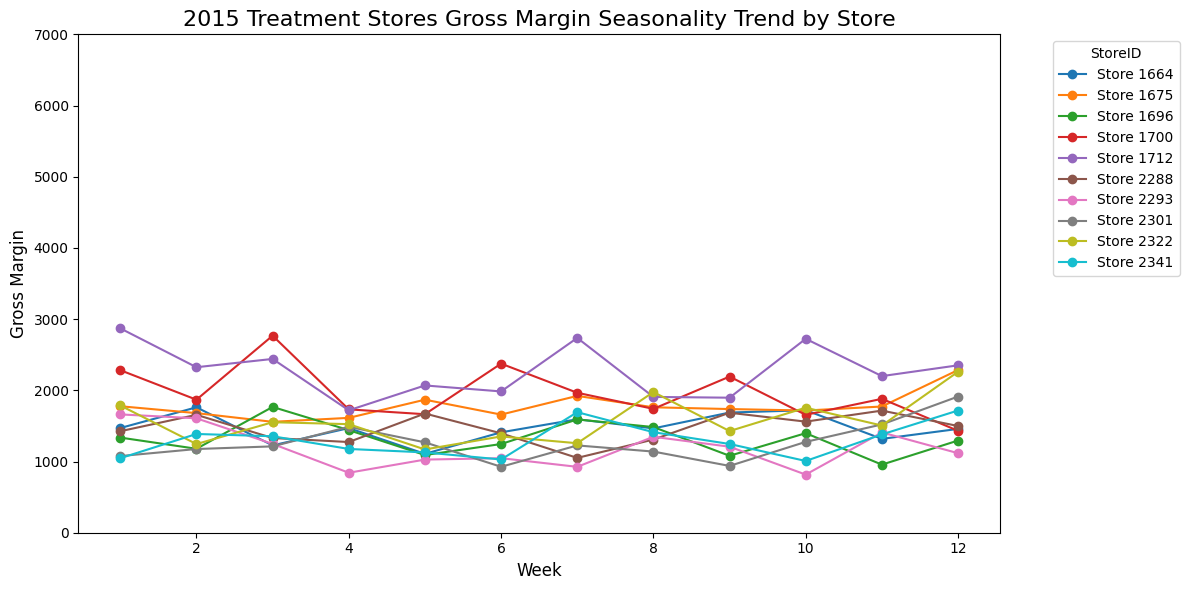

In [ ]:
# Seasonality for each treatment store in comparative period 2015
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

weekly_margin_treat2015['custom_week'] = weekly_margin_treat2015['custom_week'].str.extract('(\d+)').astype(int)
weekly_margin_treat2015 = weekly_margin_treat2015.sort_values(by=['StoreID', 'custom_week'])


unique_stores = weekly_margin_treat2015['StoreID'].unique()
plt.figure(figsize=(12, 6))
for store in unique_stores:
    store_data = weekly_margin_treat2015[weekly_margin_treat2015['StoreID'] == store]
    plt.plot(store_data['custom_week'], store_data['Gross Margin'], marker='o', label=f'Store {store}')


plt.title('2015 Treatment Stores Gross Margin Seasonality Trend by Store', fontsize=16)
plt.xlabel('Week', fontsize=12)
plt.ylabel('Gross Margin', fontsize=12)
plt.ylim(0, 7000)
plt.legend(title='StoreID', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
# Divide the test period into 12 weeks and aggregate treatment stores' profits based on `storeID` and week number.

current_year_data['Invoice Date'] = pd.to_datetime(current_year_data['Invoice Date'])
Tstart_date = pd.Timestamp('2016-04-29')
Tend_date = pd.Timestamp('2016-07-21')

custom_bins = pd.date_range(start=Tstart_date, end=Tend_date, periods=13)
current_year_data['custom_week'] = pd.cut(current_year_data['Invoice Date'], bins=custom_bins, labels=[f"Week{i+1}" for i in range(12)])

weekly_margin_treat2016 = current_year_data.groupby(['StoreID', 'custom_week'], observed=False).agg({'Gross Margin': 'sum'})
weekly_margin_treat2016['Sample Count'] = current_year_data.groupby(['StoreID', 'custom_week'], observed=False).size()
weekly_margin_treat2016 = weekly_margin_treat2016.reset_index()
print(weekly_margin_treat2016)
weekly_margin_treat2016.to_csv('/content/drive/MyDrive/Colab Notebooks/weekly_margin_treat2016.csv', index=False)

<ipython-input-16-af744e136ef2>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  current_year_data['Invoice Date'] = pd.to_datetime(current_year_data['Invoice Date'])
<ipython-input-16-af744e136ef2>:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  current_year_data['custom_week'] = pd.cut(current_year_data['Invoice Date'], bins=custom_bins, labels=[f"Week{i+1}" for i in range(12)])


     StoreID custom_week  Gross Margin  Sample Count
0       1664       Week1     1582.1250           314
1       1664       Week2     1636.7920           310
2       1664       Week3     1609.6315           304
3       1664       Week4     1096.3390           186
4       1664       Week5     1671.1075           281
..       ...         ...           ...           ...
115     2341       Week8     1721.2495           324
116     2341       Week9     2602.5615           502
117     2341      Week10     1623.1775           311
118     2341      Week11     1886.7965           383
119     2341      Week12     2411.9345           501

[120 rows x 4 columns]


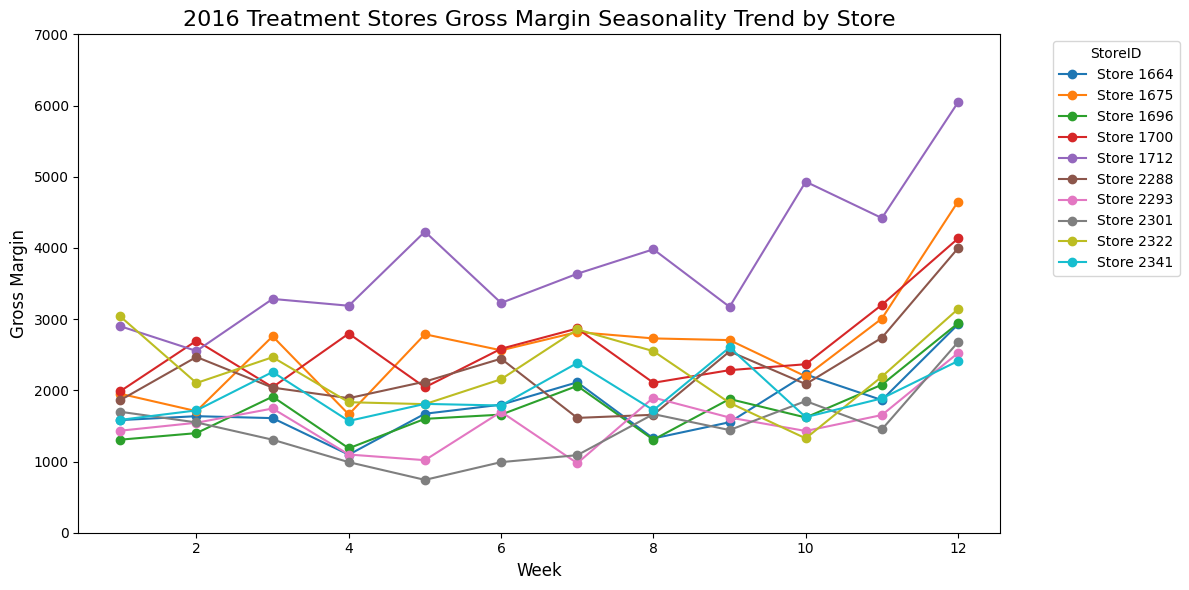

In [ ]:
# Seasonality for each treatment store in test period 2016
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

weekly_margin_treat2016['custom_week'] = weekly_margin_treat2016['custom_week'].str.extract('(\d+)').astype(int)
weekly_margin_treat2016 = weekly_margin_treat2016.sort_values(by=['StoreID', 'custom_week'])


unique_stores = weekly_margin_treat2016['StoreID'].unique()
plt.figure(figsize=(12, 6))
for store in unique_stores:
    store_data = weekly_margin_treat2016[weekly_margin_treat2016['StoreID'] == store]
    plt.plot(store_data['custom_week'], store_data['Gross Margin'], marker='o', label=f'Store {store}')


plt.title('2016 Treatment Stores Gross Margin Seasonality Trend by Store', fontsize=16)
plt.xlabel('Week', fontsize=12)
plt.ylabel('Gross Margin', fontsize=12)
plt.ylim(0, 7000)
plt.legend(title='StoreID', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Sample choosing

In [ ]:
control_stores = allstores_df[~allstores_df['StoreID'].isin(treatstores_df['StoreID'])]

control_stores

,StoreID,Sq_Ft,AvgMonthSales,Right_Name,Phone Number,Street Combined,Street 1,Street 2,Street 3,City,State,Postal Code,Region,Country,Coordinates,Latitude,Longitude,Timezone,Current Timezone Offset,Olson Timezone
0,10018,1183,18000,Bellflower & Spring,562-420-1317,"2890 N Bellflower Blvd, #A-1, The Los Altos Ma...",2890 N Bellflower Blvd,#A-1,The Los Altos Marketplace,Long Beach,CA,908151125,West,US,"(33.8085823059082, -118.124931335449)",33.808582,-118.124931,Pacific Standard Time,-480,GMT-08:00 America/Los_Angeles
1,10068,1198,16000,"Foothill & Boston, La Crescenta",818-541-7693,"3747 Foothill Boulevard, A",3747 Foothill Boulevard,A,NaN,La Cresenta,CA,912141700,West,US,"(34.2375450134277, -118.26114654541)",34.237545,-118.261146,Pacific Standard Time,-480,GMT-08:00 America/Los_Angeles
2,10118,1204,13000,Magic Mountain & Tourney,661-260-0844,"25349 Wayne Mills Place, Tourney Retail Plaza",25349 Wayne Mills Place,NaN,Tourney Retail Plaza,Valencia,CA,913551827,West,US,"(34.4237022399902, -118.579261779785)",34.423702,-118.579262,Pacific Standard Time,-480,GMT-08:00 America/Los_Angeles
3,10168,1195,19000,Alameda & Shelton,(818) 557-6604,"1190 Alameda Avenue, Suite G-2",1190 Alameda Avenue,Suite G-2,NaN,Burbank,CA,915062806,West,US,"(34.1625328063965, -118.314529418945)",34.162533,-118.314529,Pacific Standard Time,-480,GMT-08:00 America/Los_Angeles
4,10218,1193,15000,Victoria Gardens,909-646-8562,"12466 North Main Street, Space 3340, Victoria ...",12466 North Main Street,Space 3340,Victoria Gardens,Rancho Cucamonga,CA,917398886,West,US,"(34.1120910644531, -117.533462524414)",34.112091,-117.533462,Pacific Standard Time,-480,GMT-08:00 America/Los_Angeles
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
128,9768,1193,17000,Hollywood & Highland,323-962-7414,"6801 Hollywood Blvd, 257",6801 Hollywood Blvd,257,NaN,Hollywood,CA,900286136,West,US,"(34.1027717590332, -118.339248657227)",34.102772,-118.339249,Pacific Standard Time,-480,GMT-08:00 America/Los_Angeles
129,9818,1191,15000,"3rd & Gage, Los Angeles",323-265-4124,"3853 E. 3rd Street, E",3853 E. 3rd Street,E,NaN,Los Angeles,CA,900632403,West,US,"(34.0336227416992, -118.184219360352)",34.033623,-118.184219,Pacific Standard Time,-480,GMT-08:00 America/Los_Angeles
130,9868,1185,12000,"Hermosa & 13th, Hermosa Beach",310-406-8569,1303 Hermosa Avenue,1303 Hermosa Avenue,NaN,NaN,Hermosa Beach,CA,902543560,West,US,"(33.8630561828613, -118.400413513184)",33.863056,-118.400413,Pacific Standard Time,-480,GMT-08:00 America/Los_Angeles
131,9918,1190,16000,Main & Hill,(310) 392-3559,2671 Main Street,2671 Main Street,NaN,NaN,Santa Monica,CA,904054001,West,US,"(34.0011253356934, -118.482490539551)",34.001125,-118.482490,Pacific Standard Time,-480,GMT-08:00 America/Los_Angeles


In [ ]:
# area filter by range
std_dev = treatstores_df['Sq_Ft'].std()
mean_value = treatstores_df['Sq_Ft'].mean()

lower_bound = (mean_value - 1.5 * std_dev).round(2)
upper_bound = (mean_value + 1.5 * std_dev).round(2)

print(f"Lower Bound: {lower_bound}")
print(f"Upper Bound: {upper_bound}")

area_filtered = (control_stores['Sq_Ft'] >= lower_bound) & (control_stores['Sq_Ft'] <= upper_bound)
print(area_filtered.value_counts())

Lower Bound: 1368.74
Upper Bound: 1490.66
Sq_Ft
False    103
True      20
Name: count, dtype: int64


In [ ]:
# area filter by rating
control_stores['sq_ft_diff'] = abs(control_stores['Sq_Ft'] - mean_value)

sorted_area_filtered = control_stores.sort_values(by=['sq_ft_diff'])

print(sorted_area_filtered.value_counts())

StoreID  Sq_Ft  AvgMonthSales  Right_Name                           Phone Number  Street Combined                                                       Street 1                        Street 2          Street 3                         City              State  Postal Code  Region   Country  Coordinates                            Latitude   Longitude    Timezone                Current Timezone Offset  Olson Timezone                 sq_ft_diff
2014     1152   16000          Teavana - Dallas Galleria            972-788-9340  13350 DALLAS PKWY, STE 2615, Dallas Galleria                          13350 DALLAS PKWY               STE 2615          Dallas Galleria                  Dallas            TX     75240        Central  US       (32.9306373596191, -96.8210983276367)  32.930637  -96.821098   Central Standard Time   -360                     GMT-06:00 America/Chicago      277.7         1
2902     1170   17000          Outlets at San Clemente              9494418952    101 West Avenida Vista 

<ipython-input-20-f800e829ae8f>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  control_stores['sq_ft_diff'] = abs(control_stores['Sq_Ft'] - mean_value)


In [ ]:
# sales filter by rating
mean_value = treatstores_df['AvgMonthSales'].mean()

control_stores['avg_sales_diff'] = abs(control_stores['AvgMonthSales'] - mean_value)

sorted_sales_filtered = control_stores.sort_values(by=['avg_sales_diff'])

print(sorted_sales_filtered.value_counts())

StoreID  Sq_Ft  AvgMonthSales  Right_Name                           Phone Number  Street Combined                                                       Street 1                        Street 2          Street 3                         City              State  Postal Code  Region   Country  Coordinates                            Latitude   Longitude    Timezone                Current Timezone Offset  Olson Timezone                 sq_ft_diff  avg_sales_diff
2014     1152   16000          Teavana - Dallas Galleria            972-788-9340  13350 DALLAS PKWY, STE 2615, Dallas Galleria                          13350 DALLAS PKWY               STE 2615          Dallas Galleria                  Dallas            TX     75240        Central  US       (32.9306373596191, -96.8210983276367)  32.930637  -96.821098   Central Standard Time   -360                     GMT-06:00 America/Chicago      277.7       2900.0            1
2902     1170   17000          Outlets at San Clemente              94944

<ipython-input-21-510ee772416d>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  control_stores['avg_sales_diff'] = abs(control_stores['AvgMonthSales'] - mean_value)


In [ ]:
import numpy as np
control_stores['distance'] = np.sqrt(
    (control_stores['sq_ft_diff'] / control_stores['sq_ft_diff'].std())**2 +
    (control_stores['avg_sales_diff'] / control_stores['avg_sales_diff'].std())**2
)


final_selection = control_stores.nsmallest(10, 'distance')

print(final_selection[['StoreID', 'Sq_Ft', 'AvgMonthSales', 'distance']])

     StoreID  Sq_Ft  AvgMonthSales  distance
114     8917   1405          13000  0.254226
110     8717   1397          13000  0.335371
98      7584   1463          13000  0.341466
40      1508   1457          12000  0.454818
112     8817   1390          14000  0.500703
113     8867   1395          12000  0.504639
97      7534   1465          12000  0.508956
87      6992   1455          15000  0.672447
96      7484   1463          15000  0.707833
92      7284   1470          15000  0.744785


<ipython-input-22-d18621953989>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  control_stores['distance'] = np.sqrt(


# Control stores data preparation

In [ ]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')
control_file_path = '/content/drive/MyDrive/Colab Notebooks/control_data.csv'
control_df = pd.read_csv(control_file_path)
print(control_df.info())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


<ipython-input-23-053c8fda1fe4>:5: DtypeWarning: Columns (13,16,17) have mixed types. Specify dtype option on import or set low_memory=False.
  control_df = pd.read_csv(control_file_path)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009433 entries, 0 to 4009432
Data columns (total 29 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   StoreID                  int64  
 1   Invoice Number           int64  
 2   Invoice Date             object 
 3   SKU                      int64  
 4   Category                 object 
 5   Product                  object 
 6   QTY                      int64  
 7   Size                     object 
 8   Gross Margin             float64
 9   Sales                    float64
 10  Sq_Ft                    int64  
 11  AvgMonthSales            int64  
 12  Right_Name               object 
 13  Phone Number             object 
 14  Street Combined          object 
 15  Street 1                 object 
 16  Street 2                 object 
 17  Street 3                 object 
 18  City                     object 
 19  State                    object 
 20  Postal Code              int64  
 21  Region  

In [ ]:
control_df['Invoice Date'] = pd.to_datetime(control_df['Invoice Date'])
control_df['Invoice Date'].dtype

print(control_df['Invoice Date'].min(), control_df['Invoice Date'].max())

2015-01-21 00:00:00 2016-07-21 00:00:00


In [ ]:
control_df = control_df[control_df['StoreID'].isin(final_selection['StoreID'])]
print(control_df.value_counts())

last_year_data_c = control_df[
    (control_df['Invoice Date'] >= '2015-04-29') & (control_df['Invoice Date'] <= '2015-07-21')
]
print(last_year_data_c.shape)

current_year_data_c = control_df[
    (control_df['Invoice Date'] >= '2016-04-29') & (control_df['Invoice Date'] <= '2016-07-21')
]
print(current_year_data_c.shape)

StoreID  Invoice Number  Invoice Date  SKU   Category  Product     QTY  Size  Gross Margin  Sales  Sq_Ft  AvgMonthSales  Right_Name               Phone Number  Street Combined                                                       Street 1                 Street 2          Street 3                        City        State  Postal Code  Region   Country  Coordinates                            Latitude   Longitude    Timezone                Current Timezone Offset  Olson Timezone           
6992     16295153        2015-01-21    1022  Espresso  Espresso    3    M     4.4850        8.97   1455   15000          Tenth & Locust           515-280-8200  1013 Locust Street, SWC of 1st floor, The Temple for Performing Arts  1013 Locust Street       SWC of 1st floor  The Temple for Performing Arts  Des Moines  IA     503092805    Central  US       (41.5857887268066, -93.6304626464844)  41.585789  -93.630463   Central Standard Time   -360                     GMT-06:00 America/Chicago    1
8817     

# Control stores weekly trend


In [ ]:
# Divide the comparative period into 12 weeks and aggregate control sample stores' profits based on `storeID` and week number.

last_year_data_c['Invoice Date'] = pd.to_datetime(last_year_data_c['Invoice Date'])
Cstart_date = pd.Timestamp('2015-04-29')
Cend_date = pd.Timestamp('2015-07-21')

custom_bins = pd.date_range(start=Cstart_date, end=Cend_date, periods=13)
last_year_data_c['custom_week'] = pd.cut(last_year_data_c['Invoice Date'], bins=custom_bins, labels=[f"Week{i+1}" for i in range(12)])

weekly_margin_control2015 = last_year_data_c.groupby(['StoreID', 'custom_week'], observed=False).agg({'Gross Margin': 'sum'})
weekly_margin_control2015['Sample Count'] = last_year_data_c.groupby(['StoreID', 'custom_week'], observed=False).size()
weekly_margin_control2015 = weekly_margin_control2015.reset_index()
print(weekly_margin_control2015)
weekly_margin_control2015.to_csv('/content/drive/MyDrive/Colab Notebooks/weekly_margin_control2015.csv', index=False)

<ipython-input-26-2e0cb975ed54>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  last_year_data_c['Invoice Date'] = pd.to_datetime(last_year_data_c['Invoice Date'])
<ipython-input-26-2e0cb975ed54>:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  last_year_data_c['custom_week'] = pd.cut(last_year_data_c['Invoice Date'], bins=custom_bins, labels=[f"Week{i+1}" for i in range(12)])


     StoreID custom_week  Gross Margin  Sample Count
0       1508       Week1     1277.0070           327
1       1508       Week2     1664.0420           424
2       1508       Week3     1805.6745           453
3       1508       Week4     1299.5130           335
4       1508       Week5     1266.5665           324
..       ...         ...           ...           ...
115     8917       Week8     1698.9965           428
116     8917       Week9     2083.0200           539
117     8917      Week10     1437.2900           374
118     8917      Week11     1580.1245           400
119     8917      Week12     1716.1715           437

[120 rows x 4 columns]


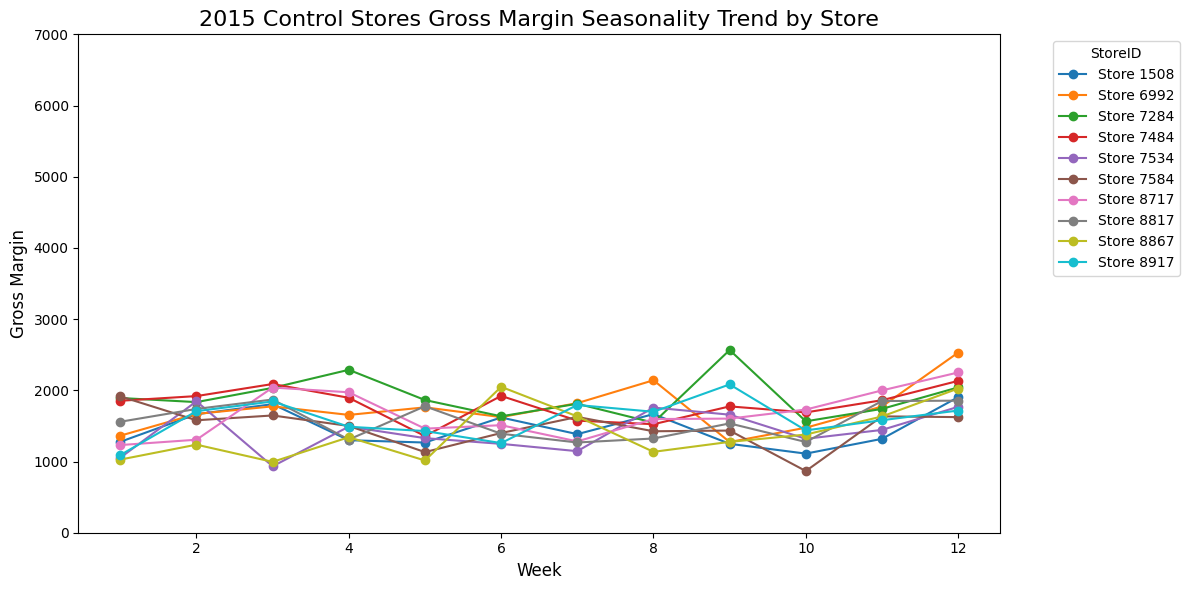

In [ ]:
# Seasonality for each control store in comparative period 2015
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

weekly_margin_control2015['custom_week'] = weekly_margin_control2015['custom_week'].str.extract('(\d+)').astype(int)
weekly_margin_control2015 = weekly_margin_control2015.sort_values(by=['StoreID', 'custom_week'])


unique_stores = weekly_margin_control2015['StoreID'].unique()
plt.figure(figsize=(12, 6))
for store in unique_stores:
    store_data = weekly_margin_control2015[weekly_margin_control2015['StoreID'] == store]
    plt.plot(store_data['custom_week'], store_data['Gross Margin'], marker='o', label=f'Store {store}')


plt.title('2015 Control Stores Gross Margin Seasonality Trend by Store', fontsize=16)
plt.xlabel('Week', fontsize=12)
plt.ylabel('Gross Margin', fontsize=12)
plt.ylim(0, 7000)
plt.legend(title='StoreID', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
# Divide the test period into 12 weeks and aggregate control stores' profits based on `storeID` and week number.

current_year_data_c['Invoice Date'] = pd.to_datetime(current_year_data_c['Invoice Date'])
Tstart_date = pd.Timestamp('2016-04-29')
Tend_date = pd.Timestamp('2016-07-21')

custom_bins = pd.date_range(start=Tstart_date, end=Tend_date, periods=13)
current_year_data_c['custom_week'] = pd.cut(current_year_data_c['Invoice Date'], bins=custom_bins, labels=[f"Week{i+1}" for i in range(12)])

weekly_margin_control2016 = current_year_data_c.groupby(['StoreID', 'custom_week'], observed=False).agg({'Gross Margin': 'sum'})
weekly_margin_control2016['Sample Count'] = current_year_data_c.groupby(['StoreID', 'custom_week'], observed=False).size()
weekly_margin_control2016 = weekly_margin_control2016.reset_index()
print(weekly_margin_control2016)
weekly_margin_control2016.to_csv('/content/drive/MyDrive/Colab Notebooks/weekly_margin_control2016.csv', index=False)

<ipython-input-28-4df0338517bb>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  current_year_data_c['Invoice Date'] = pd.to_datetime(current_year_data_c['Invoice Date'])
<ipython-input-28-4df0338517bb>:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  current_year_data_c['custom_week'] = pd.cut(current_year_data_c['Invoice Date'], bins=custom_bins, labels=[f"Week{i+1}" for i in range(12)])


     StoreID custom_week  Gross Margin  Sample Count
0       1508       Week1      974.9420           267
1       1508       Week2     1287.1880           332
2       1508       Week3     1798.4795           446
3       1508       Week4      945.2605           250
4       1508       Week5     1127.6900           290
..       ...         ...           ...           ...
115     8917       Week8     1742.8985           451
116     8917       Week9     1866.0590           478
117     8917      Week10     1348.0675           352
118     8917      Week11     1143.1540           298
119     8917      Week12     1308.3170           322

[120 rows x 4 columns]


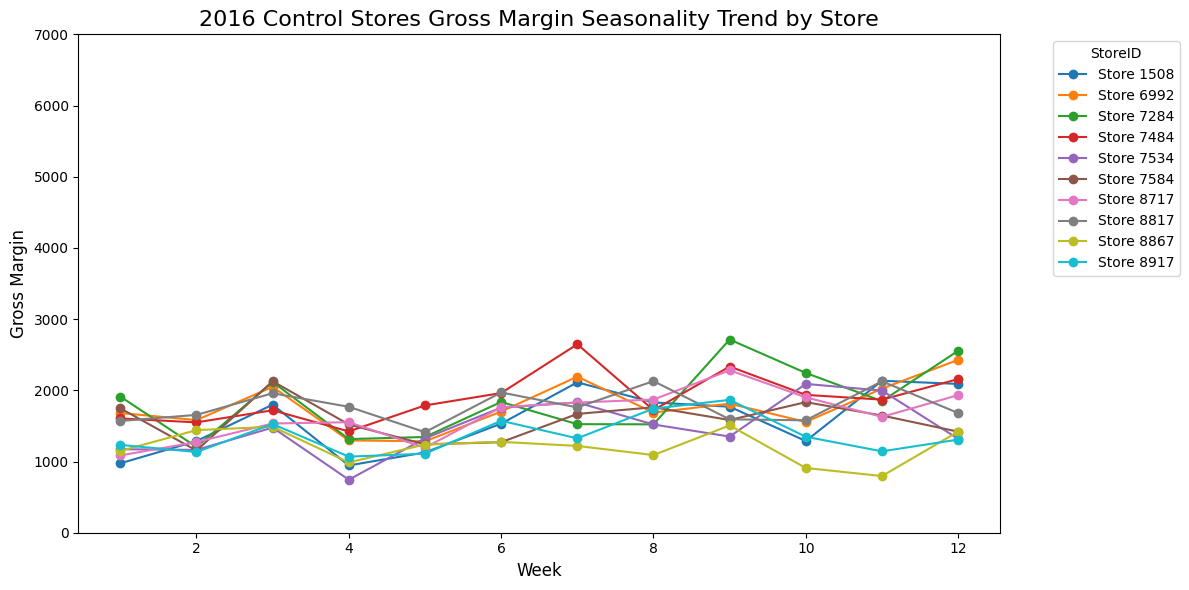

In [ ]:
# Seasonality for each control store in test period 2016
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

weekly_margin_control2016['custom_week'] = weekly_margin_control2016['custom_week'].str.extract('(\d+)').astype(int)
weekly_margin_control2016 = weekly_margin_control2016.sort_values(by=['StoreID', 'custom_week'])


unique_stores = weekly_margin_control2016['StoreID'].unique()
plt.figure(figsize=(12, 6))
for store in unique_stores:
    store_data = weekly_margin_control2016[weekly_margin_control2016['StoreID'] == store]
    plt.plot(store_data['custom_week'], store_data['Gross Margin'], marker='o', label=f'Store {store}')


plt.title('2016 Control Stores Gross Margin Seasonality Trend by Store', fontsize=16)
plt.xlabel('Week', fontsize=12)
plt.ylabel('Gross Margin', fontsize=12)
plt.ylim(0, 7000)
plt.legend(title='StoreID', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Sum and Weekly growth rate

In [2]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/Colab Notebooks/weekly_margin_treat2015.csv'
df = pd.read_csv(file_path)

# Aggregate Profit by store(Treatment stores 2015)
treat_profit_by_store2015 = df.groupby('StoreID').agg({'Gross Margin': 'sum', 'Sample Count': 'sum'}).reset_index()
treat_profit_by_store2015 = treat_profit_by_store2015.rename(columns={'Gross Margin': 'Total Profit'})

print(treat_profit_by_store2015)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   StoreID       120 non-null    int64  
 1   custom_week   120 non-null    object 
 2   Gross Margin  120 non-null    float64
 3   Sample Count  120 non-null    int64  
dtypes: float64(1), int64(2), object(1)
memory usage: 3.9+ KB
None
   StoreID  Total Profit  Sample Count
0     1664    17689.2300          4450
1     1675    21348.9325          5377
2     1696    15865.0660          4049
3     1700    23556.0925          6058
4     1712    27222.3195          7074
5     2288    17575.2420          4385
6     2293    14255.9540          3523
7     2301    15161.5310          4012
8     2322    18813.2280          4836
9     2341    15578.4235          4022


In [4]:
file_path = '/content/drive/MyDrive/Colab Notebooks/weekly_margin_treat2016.csv'
df = pd.read_csv(file_path)

# Aggregate Profit by store(Treatment stores 2016)
treat_profit_by_store2016 = df.groupby('StoreID').agg({'Gross Margin': 'sum', 'Sample Count': 'sum'}).reset_index()
treat_profit_by_store2016 = treat_profit_by_store2016.rename(columns={'Gross Margin': 'Total Profit'})

print(treat_profit_by_store2016)

   StoreID  Total Profit  Sample Count
0     1664    21394.9230          4089
1     1675    31536.6830          5621
2     1696    20946.7155          4001
3     1700    31109.6060          5671
4     1712    45566.5485          8484
5     2288    27463.4200          5609
6     2293    18636.6580          3699
7     2301    17452.7940          3304
8     2322    27290.1485          5492
9     2341    23356.2950          4578


In [5]:
treat_growth_rate = (
    (treat_profit_by_store2016["Total Profit"] - treat_profit_by_store2015["Total Profit"]) / treat_profit_by_store2015["Total Profit"]
) * 100

treat_growth_rate_df = pd.DataFrame({
    "StoreID": treat_profit_by_store2015["StoreID"],
    "Growth Rate (%)": treat_growth_rate,
    "Sample Count 2016": treat_profit_by_store2016["Sample Count"]
})

print(treat_growth_rate_df)

   StoreID  Growth Rate (%)  Sample Count 2016
0     1664        20.948865               4089
1     1675        47.720187               5621
2     1696        32.030434               4001
3     1700        32.066072               5671
4     1712        67.386723               8484
5     2288        56.261974               5609
6     2293        30.728943               3699
7     2301        15.112346               3304
8     2322        45.058299               5492
9     2341        49.927205               4578


In [7]:
treat_summary = treat_growth_rate_df['Growth Rate (%)'].agg(['count', 'max', 'min', 'median', 'mean']).reset_index()
treat_summary.columns = ['Statistic', 'Value']

print(treat_summary)

  Statistic      Value
0     count  10.000000
1       max  67.386723
2       min  15.112346
3    median  38.562185
4      mean  39.724105


In [ ]:
weighted_avg_growth_t = (treat_growth_rate_df['Growth Rate (%)'] * treat_growth_rate_df['Sample Count 2016']).sum() / treat_growth_rate_df['Sample Count 2016'].sum()
print(f"Average growth rate of treatment stores: {weighted_avg_growth_t}%")

Average growth rate of treatment stores: 43.34102995577598%


In [8]:
file_path = '/content/drive/MyDrive/Colab Notebooks/weekly_margin_control2015.csv'
df = pd.read_csv(file_path)

# Aggregate Profit by store(Control stores 2015)
control_profit_by_store2015 = df.groupby('StoreID').agg({'Gross Margin': 'sum', 'Sample Count': 'sum'}).reset_index()
control_profit_by_store2015 = control_profit_by_store2015.rename(columns={'Gross Margin': 'Total Profit'})

print(control_profit_by_store2015)

   StoreID  Total Profit  Sample Count
0     1508    17563.5815          4489
1     6992    20859.6435          5166
2     7284    22816.5725          5900
3     7484    21591.2805          5460
4     7534    16991.5365          4475
5     7584    17784.3270          4582
6     8717    19982.5965          5168
7     8817    18747.2865          4655
8     8867    16747.1605          4311
9     8917    19126.6935          4827


In [10]:
file_path = '/content/drive/MyDrive/Colab Notebooks/weekly_margin_control2016.csv'
df = pd.read_csv(file_path)

# Aggregate Profit by store(Control stores 2016)
control_profit_by_store2016 =df.groupby('StoreID').agg({'Gross Margin': 'sum', 'Sample Count': 'sum'}).reset_index()
control_profit_by_store2016 = control_profit_by_store2016.rename(columns={'Gross Margin': 'Total Profit'})

print(control_profit_by_store2016)

   StoreID  Total Profit  Sample Count
0     1508    18889.4000          4809
1     6992    21294.9160          5478
2     7284    22140.0120          5726
3     7484    22713.2020          5824
4     7534    17746.1805          4701
5     7584    18975.1420          4922
6     8717    19842.7485          5079
7     8817    21204.0760          5413
8     8867    14522.2710          3759
9     8917    16378.1495          4233


In [12]:
control_growth_rate = (
    (control_profit_by_store2016["Total Profit"] - control_profit_by_store2015["Total Profit"]) / control_profit_by_store2015["Total Profit"]
) * 100

control_growth_rate_df = pd.DataFrame({
    "StoreID": control_profit_by_store2015["StoreID"],
    "Growth Rate (%)": control_growth_rate,
    "Sample Count 2016": control_profit_by_store2016["Sample Count"]
})

print(control_growth_rate_df)

   StoreID  Growth Rate (%)  Sample Count 2016
0     1508         7.548680               4809
1     6992         2.086673               5478
2     7284        -2.965215               5726
3     7484         5.196179               5824
4     7534         4.441293               4701
5     7584         6.695868               4922
6     8717        -0.699849               5079
7     8817        13.104774               5413
8     8867       -13.285175               3759
9     8917       -14.370199               4233


In [13]:
control_summary = control_growth_rate_df['Growth Rate (%)'].agg(['count', 'max', 'min', 'median', 'mean']).reset_index()
control_summary.columns = ['Statistic', 'Value']

print(control_summary)

  Statistic      Value
0     count  10.000000
1       max  13.104774
2       min -14.370199
3    median   3.263983
4      mean   0.775303


In [ ]:
weighted_avg_growth_c = (control_growth_rate_df['Growth Rate (%)'] * control_growth_rate_df['Sample Count 2016']).sum() / control_growth_rate_df['Sample Count 2016'].sum()
print(f"Average growth rate of control stores: {weighted_avg_growth_c}%")

Average growth rate of control stores: 1.4309081978359615%


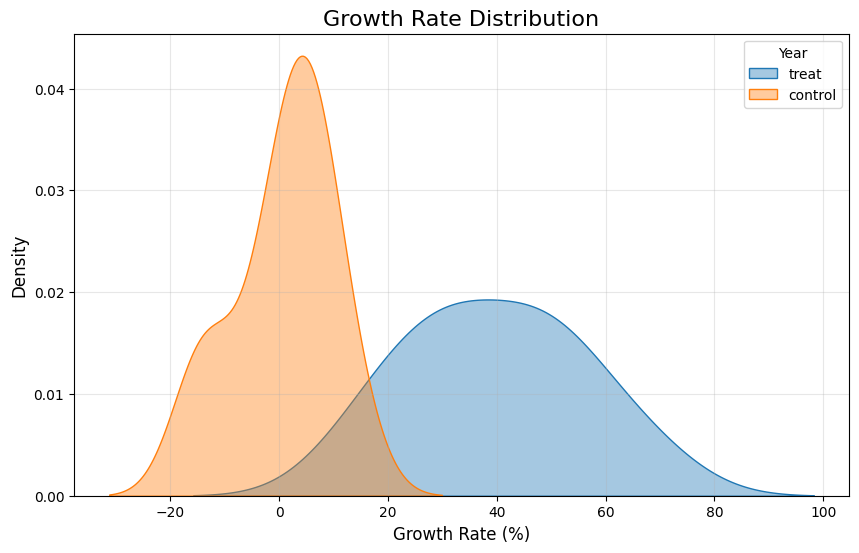

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.kdeplot(treat_growth_rate_df['Growth Rate (%)'], label='treat', fill=True, alpha=0.4)
sns.kdeplot(control_growth_rate_df['Growth Rate (%)'], label='control', fill=True, alpha=0.4)


plt.title('Growth Rate Distribution', fontsize=16)
plt.xlabel('Growth Rate (%)', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.legend(title='Year', fontsize=10)
plt.grid(alpha=0.3)
plt.show()

     StoreID  Week  Growth Rate (%)  Sample Count 2016
0       1664     1         0.075947                314
1       1664     2        -0.070844                310
2       1664     3         0.312018                304
3       1664     4        -0.253813                186
4       1664     5         0.508374                281
..       ...   ...              ...                ...
115     2341     8         0.218821                324
116     2341     9         1.088150                502
117     2341    10         0.610807                311
118     2341    11         0.366389                383
119     2341    12         0.405122                501

[120 rows x 4 columns]


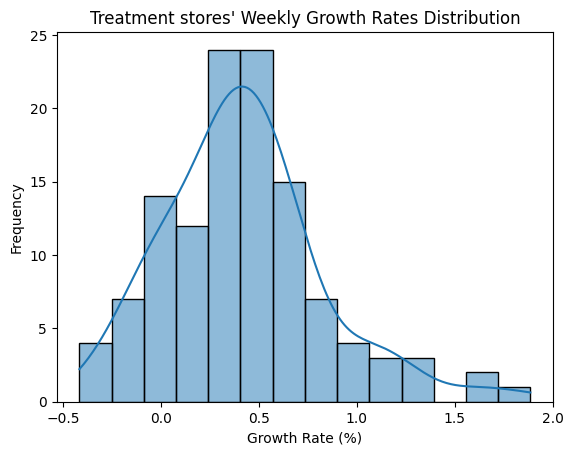

In [ ]:
weekly_treat_growth_rate = ((weekly_margin_treat2016["Gross Margin"] - weekly_margin_treat2015["Gross Margin"]) / weekly_margin_treat2015["Gross Margin"])

weekly_treat_growth_rate_df = pd.DataFrame({
    "StoreID": weekly_margin_treat2016["StoreID"],
    "Week":  weekly_margin_treat2016["custom_week"],
    "Growth Rate (%)": weekly_treat_growth_rate,
    "Sample Count 2016": weekly_margin_treat2016["Sample Count"]
})

print(weekly_treat_growth_rate_df)


sns.histplot(weekly_treat_growth_rate_df['Growth Rate (%)'], kde=True)
plt.title("Treatment stores' Weekly Growth Rates Distribution")
plt.xlabel('Growth Rate (%)')
plt.ylabel('Frequency')
plt.show()

     StoreID  Week  Growth Rate (%)  Sample Count 2016
0       1508     1        -0.236541                267
1       1508     2        -0.226469                332
2       1508     3        -0.003985                446
3       1508     4        -0.272604                250
4       1508     5        -0.109648                290
..       ...   ...              ...                ...
115     8917     8         0.025840                451
116     8917     9        -0.104157                478
117     8917    10        -0.062077                352
118     8917    11        -0.276542                298
119     8917    12        -0.237654                322

[120 rows x 4 columns]


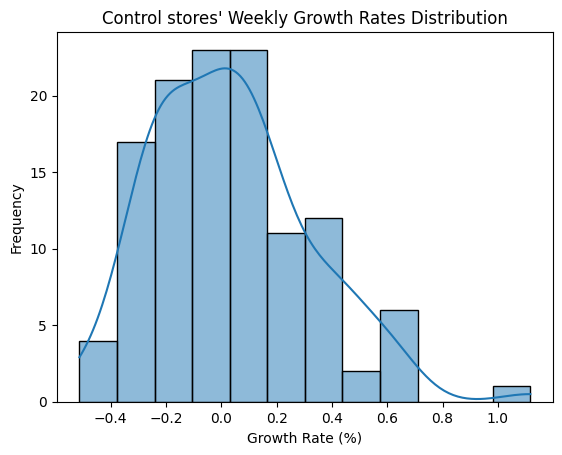

In [ ]:
weekly_control_growth_rate = ((weekly_margin_control2016["Gross Margin"] - weekly_margin_control2015["Gross Margin"]) / weekly_margin_control2015["Gross Margin"])

weekly_control_growth_rate_df = pd.DataFrame({
    "StoreID": weekly_margin_control2016["StoreID"],
    "Week":  weekly_margin_control2016["custom_week"],
    "Growth Rate (%)": weekly_control_growth_rate,
    "Sample Count 2016": weekly_margin_control2016["Sample Count"]
})

print(weekly_control_growth_rate_df)


sns.histplot(weekly_control_growth_rate_df['Growth Rate (%)'], kde=True)
plt.title("Control stores' Weekly Growth Rates Distribution")
plt.xlabel('Growth Rate (%)')
plt.ylabel('Frequency')
plt.show()

# Hypothesis testing

In [ ]:
Incremental_lift = (weighted_avg_growth_t - weighted_avg_growth_c)/weighted_avg_growth_c
if Incremental_lift >= 18:
  print(f"There is an at least 18% increase in profit growth compared to the comparative period while compared to the control stores. The incremental lift is {Incremental_lift}%.")
else:
  print(f"There is no incremental lift more than 18%.")

There is an at least 18% increase in profit growth compared to the comparative period while compared to the control stores. The incremental lift is 29.2891757985054%.


In [ ]:
# Growth rate difference test by store
from scipy.stats import ttest_ind

t_stat, p_value = ttest_ind(treat_growth_rate_df["Growth Rate (%)"], control_growth_rate_df["Growth Rate (%)"], equal_var=False)
print(f"T-Statistic: {t_stat:.4f}")
print(f"P-Value: {p_value:.4f}")


alpha = 0.05
if p_value < alpha:
    print("There is a significant difference in growth rates between the two groups.")
else:
    print("We can't admit there is a significant difference in growth rates between the two groups.")

T-Statistic: 6.6331
P-Value: 0.0000
There is a significant difference in growth rates between the two groups.


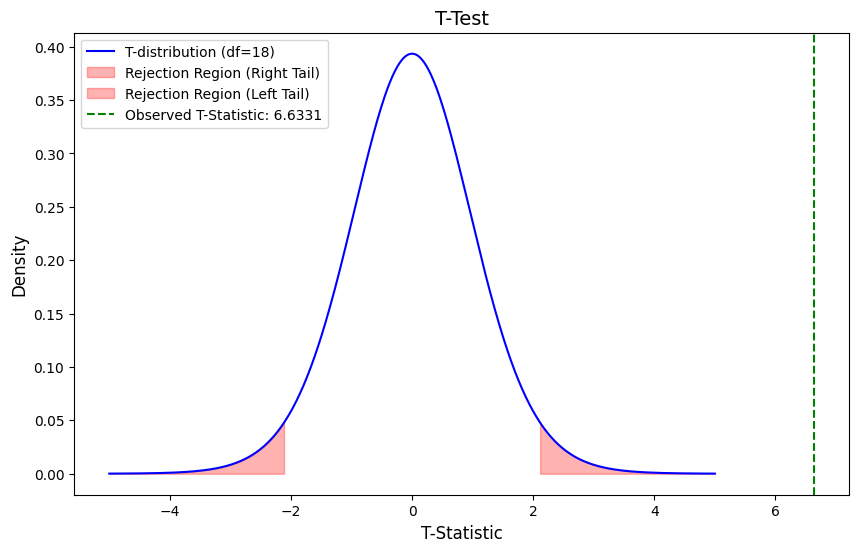

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t

# Degrees of freedom for the test (based on the sample sizes)
dof = len(treat_growth_rate_df) + len(control_growth_rate_df) - 2

# Define the T-distribution curve
x = np.linspace(-5, 5, 500)
t_dist = t.pdf(x, dof)

# Define the critical T-value for a two-tailed test at alpha = 0.05
alpha = 0.05
critical_value = t.ppf(1 - alpha / 2, dof)  # Two-tailed test, so alpha/2 for each tail

# Plot the T-distribution curve
plt.figure(figsize=(10, 6))
plt.plot(x, t_dist, label='T-distribution (df={})'.format(dof), color='blue')

# Shade the rejection regions (tails)
plt.fill_between(x, 0, t_dist, where=(x > critical_value), color='red', alpha=0.3, label='Rejection Region (Right Tail)')
plt.fill_between(x, 0, t_dist, where=(x < -critical_value), color='red', alpha=0.3, label='Rejection Region (Left Tail)')

# Plot the observed T-statistic
plt.axvline(t_stat, color='green', linestyle='--', label=f'Observed T-Statistic: {t_stat:.4f}')

# Title and labels
plt.title('T-Test', fontsize=14)
plt.xlabel('T-Statistic', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.legend()

# Show the plot
plt.show()


In [ ]:
# Growth rate difference test by store, weekly
from scipy.stats import ttest_ind

t_stat, p_value = ttest_ind(weekly_treat_growth_rate_df["Growth Rate (%)"], weekly_control_growth_rate_df["Growth Rate (%)"], equal_var=False)
print(f"T-Statistic: {t_stat:.4f}")
print(f"P-Value: {p_value:.4f}")


alpha = 0.05
if p_value < alpha:
    print("There is a significant difference in growth rates between the two groups.")
else:
    print("We can't admit there is a significant difference in growth rates between the two groups.")

T-Statistic: 8.5070
P-Value: 0.0000
There is a significant difference in growth rates between the two groups.


# Backup

In [ ]:
# Balance two groups by choosing the smallest sample of every StoreID. After that, there is no difference.
min_sample_size = store_balance[['Last Year', 'Current Year']].min(axis=1)

def balance_samples(data, min_samples):
    balanced_data = pd.DataFrame()
    for store_id, n_samples in min_samples.items():
        store_data = data[data['StoreID'] == store_id]
        balanced_data = pd.concat([balanced_data, store_data.sample(n=int(n_samples), random_state=42)])
    return balanced_data

balanced_last_year_data = balance_samples(last_year_data, min_sample_size)
balanced_current_year_data = balance_samples(current_year_data, min_sample_size)

In [ ]:
# 按比例抽取样本
sale_groups = allstores_df.groupby('AvgMonthSales')

def balanced_sampling(group, target_store, num_samples=3):
    group = group.sort_values(by=['region_match', 'sq_ft_diff'], ascending=[False, True])
    return group.head(num_samples)


sampled_df = sale_groups.apply(lambda group: balanced_sampling(group, control_df, num_samples=10))

sampled_df = sampled_df.reset_index(drop=True)
print(sampled_df)

KeyError: 'region_match'

In [ ]:
last_year_mean = last_year_data.groupby('StoreID')['Gross Margin'].mean()
current_year_mean = current_year_data.groupby('StoreID')['Gross Margin'].mean()

treat_growth_rate = (
    (current_year_mean - last_year_mean) / last_year_mean
)* 100

print(treat_growth_rate)


In [ ]:
last_year_c_mean = last_year_data_c.groupby('StoreID')['Gross Margin'].mean()
current_year_c_mean = current_year_data_c.groupby('StoreID')['Gross Margin'].mean()

control_growth_rate = (
    (current_year_c_mean - last_year_c_mean) / last_year_c_mean
)* 100

print(control_growth_rate)